# Customer Segmentation with Clustering
**Goal:** segment a set of wholesale customers into groups using k-means, decide how many
groups with the **elbow method** and the **silhouette score**, and explain what each segment is.



## Your dataset

Use the **Wholesale Customers** dataset: annual spending (monetary units) by 440 clients of a
wholesale distributor across product categories.

- Download: [UCI Wholesale Customers](https://archive.ics.uci.edu/dataset/292/wholesale+customers) (also searchable as "Wholesale customers" on Kaggle).
- Columns: `Channel`, `Region` (these are labels, not spending), then the six spend columns `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`.
- Cluster on the **six spend columns**. `Channel` and `Region` are context only; do not cluster on them.

In [1]:
# Step 0: imports (given - just run this)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

ETSU_NAVY = "#00053E"
ETSU_GOLD = "#FFC72C"
print("Ready.")

Ready.


## Step 1: Load the data

Change the path to the real Wholesale file when you have it.

In [2]:
# GIVEN: load the data
df = pd.read_csv("wholesale_sample.csv")
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1,1,4181,10024,26577,1979,9194,1151
1,2,3,3346,4848,14310,1155,2666,1768
2,2,3,3687,8096,10837,870,7701,1345
3,1,2,3008,6327,16926,1032,5303,1582
4,2,3,4704,13163,20537,1507,3073,1267


## Step 2: Explore

Look at the data before clustering: size, column types, and the ranges of the spend columns
(the ranges tell you whether scaling is needed).

In [3]:
# check size, types, missing values, and ranges
print("Rows, columns:", df.shape)
print("\nMissing values per column:")
print(df.isnull().sum())

# ranges of the spend columns -> very different, so we need to scale
summary = df[spend_cols].describe().T[["mean", "min", "max"]].round(0)
summary

Rows, columns: (150, 8)

Missing values per column:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


,mean,min,max
Fresh,10299.0,2043.0,35404.0
Milk,5423.0,1313.0,18274.0
Grocery,7938.0,1451.0,34411.0
Frozen,3017.0,760.0,8236.0
Detergents_Paper,2982.0,318.0,12186.0
Delicassen,1809.0,483.0,5332.0


## Step 3: Select features and scale

k-means uses distance, and these spend columns are on very different scales, so scale them.

- Build X from the six spend columns.
- Scale with StandardScaler.

In [4]:
# features = the 6 spend columns only
X = df[spend_cols]

scaler = StandardScaler()
Xs = scaler.fit_transform(X)

# put it back in a dataframe so it's easier to look at
scaled_df = pd.DataFrame(Xs, columns=spend_cols)
scaled_df.describe().loc[["mean", "std"]].round(2)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
mean,0.0,0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


## Step 4: Choose the number of clusters (elbow + silhouette)

Try a range of k (say 2 to 10). For each k, fit k-means and record two things:

- `kmeans.inertia_` for the **elbow** plot (tightness; look for where the curve bends),
- `silhouette_score(Xs, labels)` for the **silhouette** plot (separation; higher is better).

Plot both, then pick a k and justify it in a sentence.

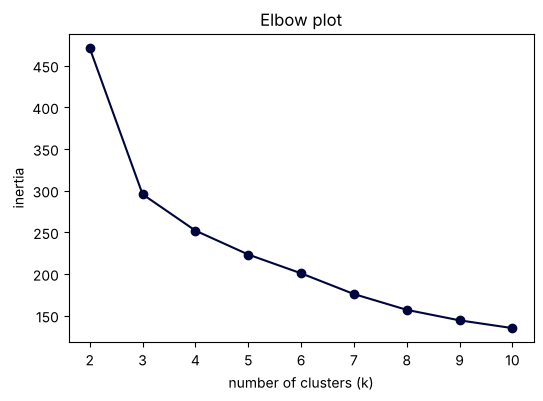

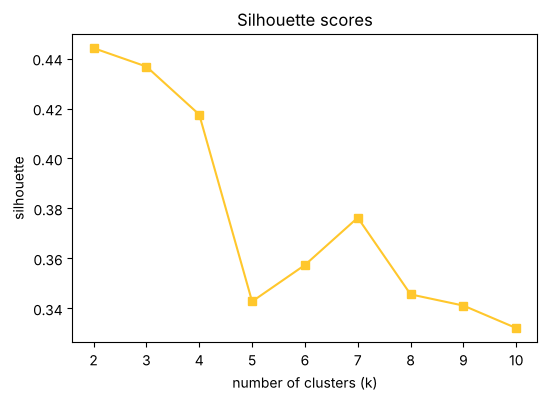

,k,inertia,silhouette
0,2,470.925,0.444
1,3,295.536,0.437
2,4,251.922,0.418
3,5,223.222,0.343
4,6,200.660,0.357
5,7,175.780,0.376
6,8,156.835,0.346
7,9,144.240,0.341
8,10,134.917,0.332


In [5]:
# try k from 2 to 10 and save the inertia + silhouette for each
results = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(Xs)
    results.append({"k": k,
                    "inertia": model.inertia_,
                    "silhouette": silhouette_score(Xs, labels)})

results = pd.DataFrame(results)

# elbow plot
plt.figure(figsize=(6, 4))
plt.plot(results["k"], results["inertia"], marker="o", color=ETSU_NAVY)
plt.title("Elbow plot"); plt.xlabel("number of clusters (k)"); plt.ylabel("inertia")
plt.show()

# silhouette plot
plt.figure(figsize=(6, 4))
plt.plot(results["k"], results["silhouette"], marker="s", color=ETSU_GOLD)
plt.title("Silhouette scores"); plt.xlabel("number of clusters (k)"); plt.ylabel("silhouette")
plt.show()

results.round(3)

**Your chosen k and why:**

I went with k = 3 since the inertia drops a lot from 2 to 3 and then flattens out, and the silhouette at 3 is only a tiny bit lower than at 2.

## Step 5: Fit k-means with your chosen k

In [6]:
best_k = 3
final_km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["cluster"] = final_km.fit_predict(Xs)

print("Customers per cluster:")
print(df["cluster"].value_counts().sort_index())

Customers per cluster:
cluster
0    54
1    53
2    43
Name: count, dtype: int64


## Step 6: Visualize the clusters with PCA

You have six features, so you cannot plot them directly. Reduce the scaled data to 2D with PCA
and color the points by cluster.

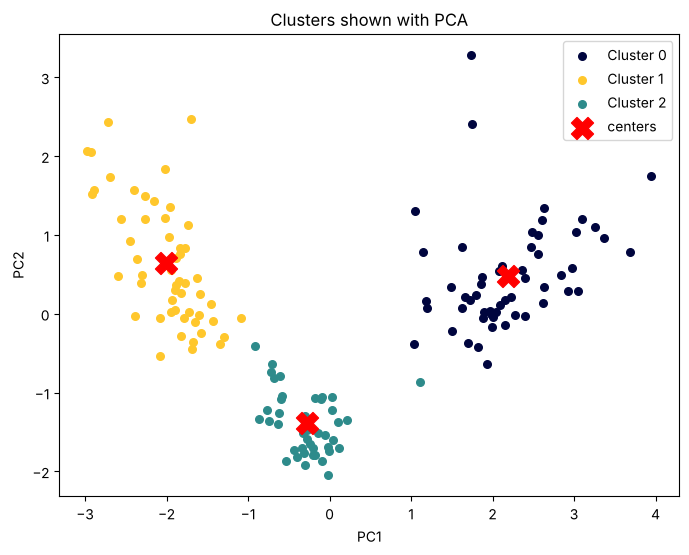

In [7]:
# shrink 6 features down to 2 so we can see the clusters
pca = PCA(n_components=2)
pca_points = pca.fit_transform(Xs)
df["PC1"] = pca_points[:, 0]
df["PC2"] = pca_points[:, 1]

# also put the cluster centers into the same 2D space
centers_2d = pca.transform(final_km.cluster_centers_)

colors = [ETSU_NAVY, ETSU_GOLD, "#2E8B8B"]
plt.figure(figsize=(8, 6))
for cl, group in df.groupby("cluster"):
    plt.scatter(group["PC1"], group["PC2"], color=colors[cl], s=30, label=f"Cluster {cl}")
plt.scatter(centers_2d[:, 0], centers_2d[:, 1], marker="X", s=250, color="red", label="centers")
plt.title("Clusters shown with PCA")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.legend()
plt.show()

## Step 7: Profile and interpret the segments

Summarize each cluster by the average of each spend column (and how many customers are in it),
then describe each segment in plain words.

In [8]:
# average spending in each cluster + how many customers
profile = df.groupby("cluster").agg(
    customers=("Fresh", "count"),
    fresh=("Fresh", "mean"),
    milk=("Milk", "mean"),
    grocery=("Grocery", "mean"),
    frozen=("Frozen", "mean"),
    detergents_paper=("Detergents_Paper", "mean"),
    delicassen=("Delicassen", "mean"),
).round(0)
profile

,customers,fresh,milk,grocery,frozen,detergents_paper,delicassen
cluster,,,,,,,
0,54,4160.0,9696.0,15961.0,1548.0,6345.0,1668.0
1,53,20406.0,3157.0,3714.0,5268.0,810.0,2441.0
2,43,5550.0,2849.0,3070.0,2089.0,1435.0,1207.0


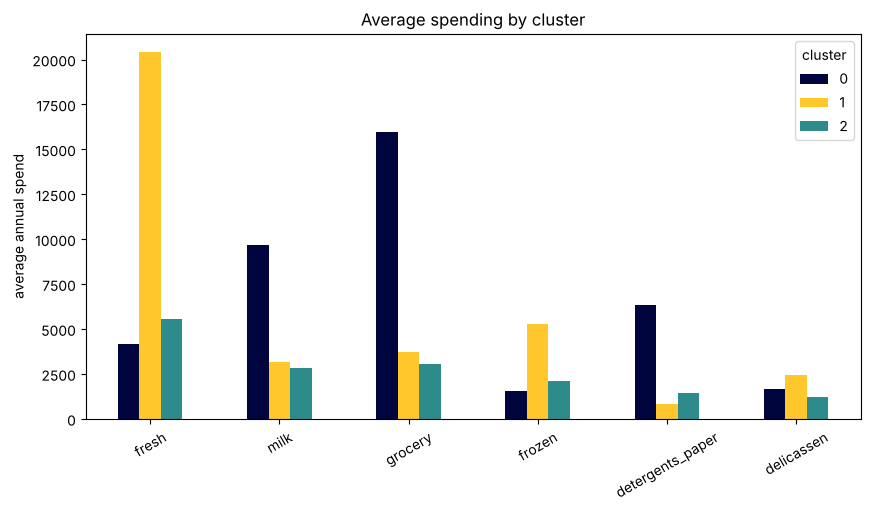

In [9]:
# bar chart of the averages to compare the clusters easier
profile.drop(columns="customers").T.plot(kind="bar", figsize=(10, 5),
                                         color=[ETSU_NAVY, ETSU_GOLD, "#2E8B8B"])
plt.title("Average spending by cluster")
plt.ylabel("average annual spend")
plt.xticks(rotation=30)
plt.show()

## Step 8: Findings

1. **How many clusters did you choose, and why?**
I used 3 clusters because the elbow flattens out after 3 and the silhouette score was still close to its highest there.

2. **Describe each segment**
- 1, Stores that mostly buy grocery, milk, and cleaning/paper products to resell.
- 2, Food businesses like restaurants that mostly buy fresh and frozen items.
- 3, Smaller buyers who don't spend much in any category.

3. **One action per segment**
- 1, Offer volume discounts on packaged goods so they keep ordering in bulk.
- 2,  Set up regular fresh and frozen deliveries so they always have stock.
- 3, Offer small discounts or bundles to try to grow how much they buy.

4. **One limitation**
A few customers spend way more than everyone else and that can skew k-means, so I'd want to try a log transform on the spending columns to see if the clusters change.

## Submission checklist

- This notebook, renamed `Lastnames_Clustering.ipynb`, all cells run with output showing